# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Анализ больших данных и рыночных тенденций»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Формат:** интерактивный ноутбук Google Colab · до 100 баллов · срок сдачи — по графику курса

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» поля (цены, остатки, зарплатные вилки, даты, технологии в тексте требований) регулярными выражениями.
4. Собрать единый `pandas.DataFrame`, провести разведочный анализ и построить корректные графики.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**: она должна показать «Выполнено: 11 из 11».

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — нижняя граница для учебной работы. Сервер, который вы «положите», принадлежит другим людям.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Выводы по аварийным данным не принимаются** — повторите сбор, когда источник снова доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [1]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 8              #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "student@mgpu.ru"  #@param {type:"string"}
USE_CACHE = True          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path

if not Path('/content').exists():
    os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.mplconfig'))
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache_v2" if Path("/content").exists() else "pw1_cache_v2")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            # API может прислать application/json без charset; декодируем UTF-8 явно.
            data = json.loads(r.content.decode("utf-8-sig"))
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.content.decode("utf-8", errors="replace")
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.12 | requests 2.x | bs4 4.x | lxml 6.x | pandas 3.x | seaborn 0.13
Вариант: 8 | кэш: pw1_cache_v2 | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Если пауза меньше 0,5 с, увеличьте её: при сборе десятков страниц это разница между «данные собраны» и «IP временно заблокирован».

In [2]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 8 — E-commerce
Бизнес-задача: Влияние рейтинга на цену: есть ли премия за качество

Источник API : api.github.com — поиск публичных репозиториев
Параметры API: {'q': 'recommender system', 'sort': 'stars', 'pages': 2, 'per_page': 50}
Сайт парсинга: books.toscrape.com
Параметры    : {'category': 'romance_8', 'pages': 4}

Метрики: scatter «рейтинг — цена» с линией тренда, сравнение медиан, топ репозиториев


## Паспорт источников и дизайн выборки

**Вариант 8.** Бизнес-задача — проверить, связана ли цена книги с пользовательским рейтингом, и сопоставить исследование с открытыми проектами рекомендательных систем.

| Контур | Источник | Что собираем | Доступ и ограничения |
|---|---|---|---|
| REST API | [GitHub Search API](https://api.github.com/search/repositories) | 100 репозиториев по запросу `recommender system`: звёзды, форки, язык, даты обновления | Без ключа допустим ограниченный объём; 2 страницы по 50 записей, пауза, ретраи и кэш |
| HTML | [Books to Scrape](https://books.toscrape.com/) | Название, цена, наличие и рейтинг книг категории Romance | Учебный статический сайт; BeautifulSoup и XPath, пауза и кэш |

В категории `romance_8` находится 35 книг, поэтому для выполнения минимального требования в 40 HTML-объектов выборка прозрачно дополнена уникальными карточками общего каталога. Поле `scope` отделяет 35 профильных книг от расширения. Основные выводы о связи рейтинга и цены рассчитываются по профильной категории Romance.

Дата сбора сохраняется в выводах. Токены, персональные данные и приватные репозитории не используются.

### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [3]:
#@title Шаг 2. Сбор данных через GitHub Search API — решение { display-mode: "form" }
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"

def _optional_github_token():
    """Необязательный токен: Colab Secrets или переменная окружения; интерактивный ввод не нужен."""
    try:
        from google.colab import userdata
        value = userdata.get("GITHUB_TOKEN")
        if value:
            return value
    except Exception:
        pass
    return os.environ.get("GITHUB_TOKEN")

def fetch_api(cfg):
    if cfg["api"] != "github":
        raise ValueError("Решение этой версии подготовлено для GitHub API варианта 8")
    p = cfg["api_params"]
    headers = {"Accept": "application/vnd.github+json"}
    token = _optional_github_token()
    if token:
        headers["Authorization"] = f"Bearer {token}"
    rows = []
    for page in range(1, p["pages"] + 1):
        params = {"q": p["q"], "sort": p.get("sort", "stars"), "order": "desc",
                  "per_page": p["per_page"], "page": page}
        data, meta = polite_get(GITHUB_SEARCH_URL, params=params, headers=headers)
        if data is None:
            print(f"Страница {page}: ошибка — {meta.get('error')}")
            break
        batch = data.get("items", [])
        print(f"Страница {page}: {len(batch)} репозиториев; кэш={meta['from_cache']}; "
              f"остаток лимита={meta.get('limit_remaining')}")
        rows.extend(batch)
        if len(batch) < p["per_page"]:
            break
    return rows

def normalize_api(raw, source):
    if source != "github":
        raise ValueError(f"Неподдерживаемый источник: {source}")
    return [{
        "full_name": item.get("full_name"),
        "owner": (item.get("owner") or {}).get("login"),
        "name": item.get("name"),
        "description": item.get("description") or "",
        "html_url": item.get("html_url"),
        "language": item.get("language"),
        "stars": item.get("stargazers_count"),
        "forks": item.get("forks_count"),
        "open_issues": item.get("open_issues_count"),
        "created_at": item.get("created_at"),
        "updated_at": item.get("updated_at"),
        "archived": bool(item.get("archived")),
        "topics": ", ".join(item.get("topics") or []),
    } for item in raw]

raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
print(f"Собрано записей: {len(df_api)}")
display(df_api.head())

Страница 1: 50 репозиториев; кэш=False
Страница 2: 50 репозиториев; кэш=False
Ключи первой записи: ['archived', 'created_at', 'description', 'forks_count', 'full_name', 'html_url', 'language', 'name', 'open_issues_count', 'owner', 'stargazers_count', 'topics', 'updated_at']
Собрано записей: 100

full_name                              language          stars   forks  open_issues
recommenders-team/recommenders         Python              21952    3323         180
gorse-io/gorse                         Go                   9876     918         121
NirantK/awesome-project-ideas          —                    9341    1291           7
NicolasHug/Surprise                    Python               6819    1048          80
hongleizhang/RSPapers                  —                    6519    1342           1


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если в выводе появилось предупреждение об аварийном режиме, значит источник недоступен: пайплайн продолжит работу на синтетических данных, но выводы по ним недопустимы.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [4]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath — решение { display-mode: "form" }
from urllib.parse import urljoin

SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    }
}


def parse_with_bs4(page_html, site):
    cfg = SITES[site]
    soup = BeautifulSoup(page_html, "html.parser")
    rows = []
    for item in soup.select(cfg["item_css"]):
        row = {}
        for field, (selector, attr) in cfg["fields_css"].items():
            element = item.select_one(selector)
            if element is None:
                row[field] = None
            elif attr == "text":
                row[field] = element.get_text(" ", strip=True)
            elif attr == "class":
                row[field] = " ".join(element.get("class", []))
            else:
                row[field] = element.get(attr)
        rows.append(row)
    return rows


def parse_with_xpath(page_html, site):
    cfg = SITES[site]
    tree = lxml_html.fromstring(page_html)
    rows = []
    for node in tree.xpath(cfg["item_xpath"]):
        row = {}
        for field, expression in cfg["fields_xpath"].items():
            values = node.xpath(expression)
            cleaned = [re.sub(r"\s+", " ", v if isinstance(v, str) else v.text_content()).strip()
                       for v in values]
            cleaned = [v for v in cleaned if v]
            row[field] = " ".join(cleaned) if cleaned else None
        rows.append(row)
    return rows


def collect_site(site, pages=3, **site_params):
    """Собрать профильную категорию и, если она мала, прозрачно расширить каталог."""
    cfg = SITES[site]
    bs_rows, xp_rows = [], []

    def add_page(page_url, page_no, scope):
        page_html, meta = polite_get(page_url, expect="text")
        if page_html is None:
            print(f"HTML {page_no}: ошибка — {meta.get('error')}")
            return False
        left, right = parse_with_bs4(page_html, site), parse_with_xpath(page_html, site)
        for rows in (left, right):
            for row in rows:
                row["url"] = urljoin(page_url, row.get("url") or "")
                row["source_page"] = page_no
                row["scope"] = scope
        print(f"HTML {scope}, страница {page_no}: BS4={len(left)}, XPath={len(right)}")
        if not left:
            return False
        bs_rows.extend(left)
        xp_rows.extend(right)
        return True

    for page in range(1, pages + 1):
        url = cfg["page_url"](page, **site_params)
        count_before = len(bs_rows)
        if not add_page(url, page, site_params.get("category", "category")):
            break
        if len(bs_rows) - count_before < 20:
            print("Категория исчерпана: получена неполная страница.")
            break

    # Если профильная категория меньше минимума, прозрачно расширяем общий каталог до 40 объектов.
    page = 1
    while len({r.get("title") for r in bs_rows}) < 40 and page <= 5:
        url = f"https://books.toscrape.com/catalogue/page-{page}.html"
        add_page(url, page, "catalogue_expansion")
        page += 1

    def deduplicate(rows):
        seen, unique = set(), []
        for row in rows:
            key = row.get("title") or row.get("url")
            if key not in seen:
                seen.add(key)
                unique.append(row)
        return unique

    return deduplicate(bs_rows), deduplicate(xp_rows)


rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]
titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")
display(df_web.head())

HTML romance_8, страница 1: BS4=20, XPath=20
HTML romance_8, страница 2: BS4=15, XPath=15
Категория исчерпана: получена неполная страница.
HTML catalogue_expansion, страница 1: BS4=20, XPath=20
Карточек: 55 | совпадение BS4 и XPath: 55 из 55

title                                             price  rating  stock  scope
Chase Me (Paris Nights #2)                         25.27       5      1  romance_8
Black Dust                                         34.53       5      1  romance_8
Her Backup Boyfriend (The Sorensen Family #1)      33.97       1      1  romance_8
First and First (Five Boroughs #3)                 15.97       4      1  romance_8
Fifty Shades Darker (Fifty Shades #2)              21.96       1      1  romance_8


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Проверьте также, что число карточек соответствует ожидаемому (на учебной витрине — 20 на страницу) и что в таблице нет колонок, целиком заполненных `None`: пустая колонка — это почти всегда устаревший селектор, а не отсутствие данных на сайте.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [5]:
#@title Шаг 4. Очистка данных регулярными выражениями — решение { display-mode: "form" }
NBSP = "\u00a0\u202f\u2009"

def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()

def parse_price(text):
    match = re.search(r"(?P<num>\d+(?:[ \u00a0\u202f\u2009]\d{3})*(?:[.,]\d{1,2})?)", str(text or ""))
    return float(re.sub(r"[ \u00a0\u202f\u2009]", "", match.group("num")).replace(",", ".")) if match else None

def parse_stock(text):
    value = normalize_ws(text).lower()
    if "out of stock" in value:
        return 0
    match = re.search(r"\((?P<n>\d+)\s*available\)", value)
    return int(match.group("n")) if match else (1 if "in stock" in value else None)

def parse_rating(class_text):
    words = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
    match = re.search(r"\b(one|two|three|four|five)\b", str(class_text or ""), re.I)
    return words[match.group(1).lower()] if match else None

def parse_date(text):
    match = re.search(r"^\d{4}-\d{2}-\d{2}", normalize_ws(text))
    return pd.to_datetime(match.group(0), errors="coerce") if match else pd.NaT

CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_date, "2026-03-15T12:00:00Z", pd.Timestamp("2026-03-15")),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print("Регулярные выражения прошли проверку")

df_web["price"] = df_web["price_text"].map(parse_price)
df_web["stock"] = df_web["availability_text"].map(parse_stock).astype("Int64")
df_web["rating"] = df_web["rating_class"].map(parse_rating).astype("Int64")
df_api["stars"] = pd.to_numeric(df_api["stars"], errors="coerce")
df_api["forks"] = pd.to_numeric(df_api["forks"], errors="coerce")
df_api["open_issues"] = pd.to_numeric(df_api["open_issues"], errors="coerce")
df_api["created_date"] = df_api["created_at"].map(parse_date)
df_api["updated_date"] = df_api["updated_at"].map(parse_date)

quality = pd.DataFrame({
    "поле": ["цена", "остаток", "рейтинг", "звёзды", "дата создания"],
    "распознано, %": [df_web["price"].notna().mean(), df_web["stock"].notna().mean(),
                       df_web["rating"].notna().mean(), df_api["stars"].notna().mean(),
                       df_api["created_date"].notna().mean()]
})
quality["распознано, %"] = (quality["распознано, %"] * 100).round(1)
display(quality)
display(df_web[["title", "price", "rating", "stock", "scope"]].head(3))
display(df_api[["full_name", "language", "stars", "forks", "created_date"]].head(3))

Регулярные выражения прошли проверку

поле             распознано, %
цена                     100.0
остаток                  100.0
рейтинг                  100.0
звёзды                   100.0
дата создания            100.0

title                                             price  rating  stock  scope
Chase Me (Paris Nights #2)                         25.27       5      1  romance_8
Black Dust                                         34.53       5      1  romance_8
Her Backup Boyfriend (The Sorensen Family #1)      33.97       1      1  romance_8

full_name                              language          stars   forks  open_issues
recommenders-team/recommenders         Python              21952    3323         180
gorse-io/gorse                         Go                   9876     918         121
NirantK/awesome-project-ideas          —                    9341    1291           7


**Как читать вывод.** Сначала блок проверки регулярных выражений: пока он не показывает «все ок», данные трогать рано. Затем таблица качества очистки — доля распознанных значений по каждому источнику. Ориентир: не ниже 80 %. Если ниже, ищите формат, который выражение не покрывает (обычно это неразрывный пробел, диапазон «от … до …» или валюта, записанная словом). Помните: строки с нераспознанной ценой не исчезают — они превращаются в пропуски и молча уменьшают выборку.

### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

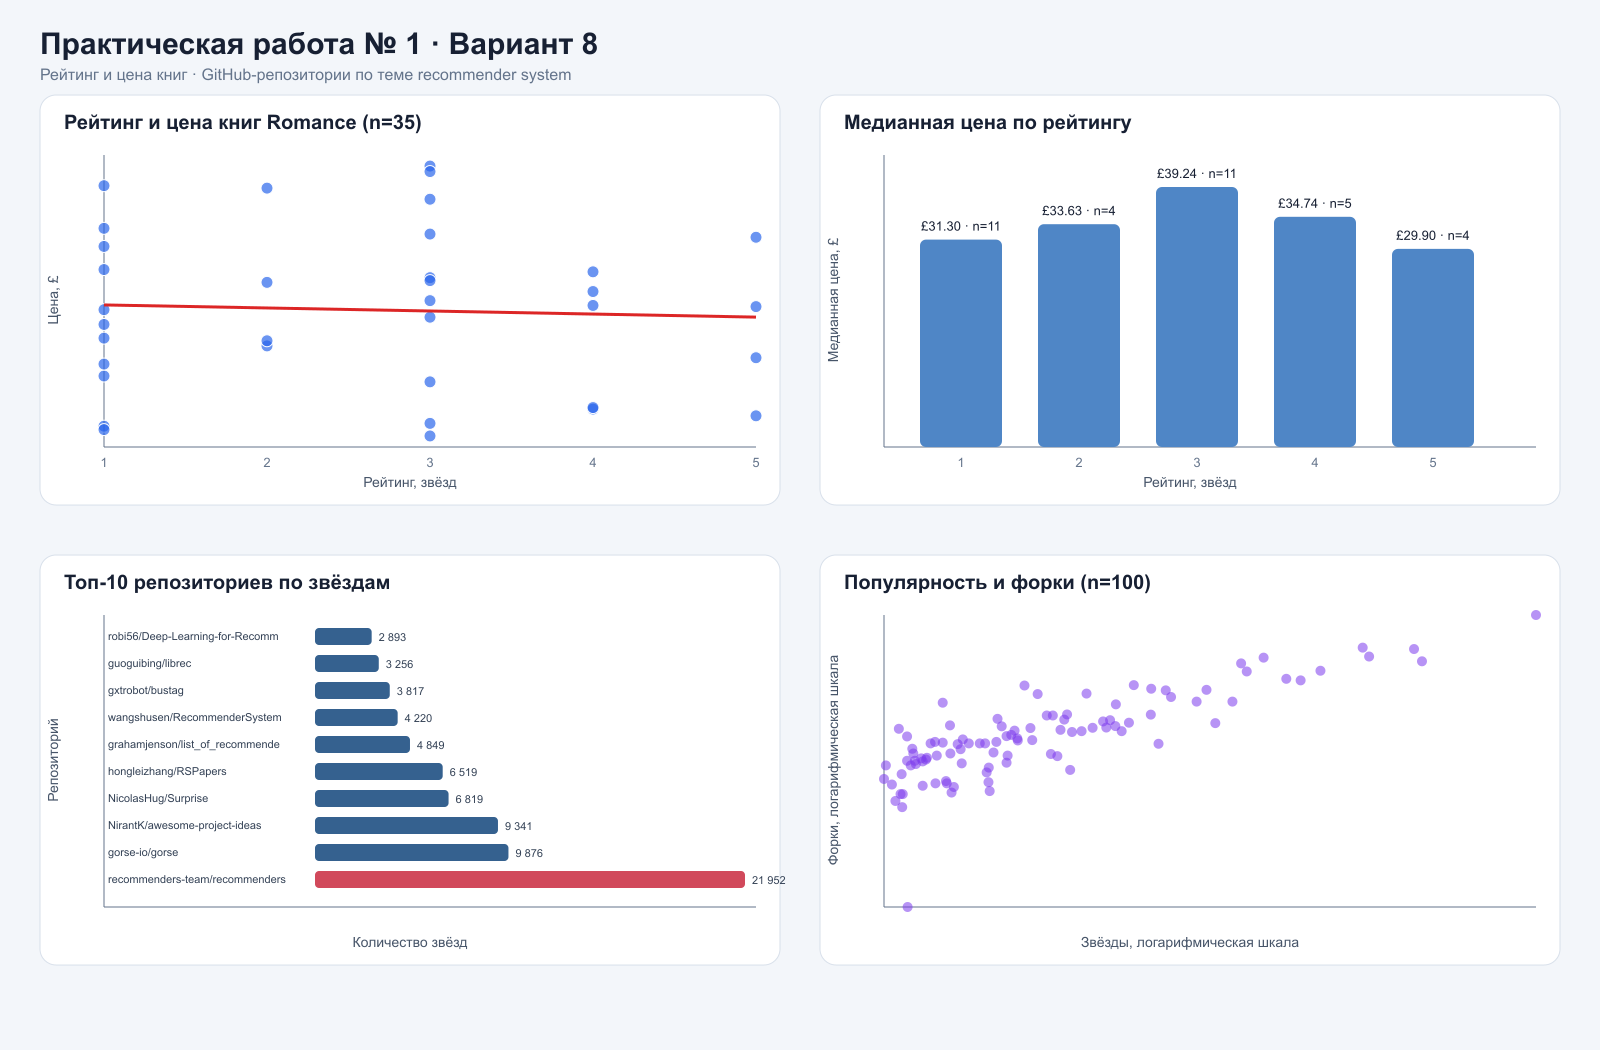

In [6]:
#@title Шаг 5. Разведочный анализ и визуализация — вариант 8 { display-mode: "form" }
profile_books = df_web[df_web["scope"] == CFG["site_params"]["category"]].dropna(subset=["price", "rating"]).copy()
profile_books["rating_num"] = profile_books["rating"].astype(float)
rating_stats = profile_books.groupby("rating", observed=True)["price"].agg(["median", "count"]).reset_index()
top_repos = df_api.nlargest(10, "stars").sort_values("stars")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.regplot(data=profile_books, x="rating_num", y="price", scatter_kws={"alpha": .7},
            line_kws={"color": "#d1495b"}, ax=axes[0, 0])
axes[0, 0].set(title=f"Рейтинг и цена книг Romance (n={len(profile_books)})",
               xlabel="Рейтинг, звёзд", ylabel="Цена, £")

sns.barplot(data=rating_stats, x="rating", y="median", hue="rating", legend=False,
            palette="Blues_d", ax=axes[0, 1])
for i, row in rating_stats.iterrows():
    axes[0, 1].text(i, row["median"] + .6, f"n={int(row['count'])}", ha="center", fontsize=9)
axes[0, 1].set(title="Медианная цена по рейтингу", xlabel="Рейтинг, звёзд", ylabel="Медианная цена, £")

axes[1, 0].barh(top_repos["full_name"], top_repos["stars"], color="#35618f")
axes[1, 0].set(title=f"Топ-10 GitHub-репозиториев (n={len(df_api)})",
               xlabel="Количество звёзд", ylabel="Репозиторий")

languages = df_api["language"].fillna("Не указан")
sns.scatterplot(data=df_api, x="stars", y="forks", hue=languages, alpha=.72, ax=axes[1, 1])
axes[1, 1].set_xscale("log")
axes[1, 1].set_yscale("log")
axes[1, 1].set(title="Звёзды и форки GitHub-проектов", xlabel="Звёзды, лог. шкала", ylabel="Форки, лог. шкала")
axes[1, 1].legend(title="Язык", fontsize=8)

fig.suptitle("Вариант 8 — есть ли ценовая премия за рейтинг", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

**Как читать вывод.** На scatter-графике линия тренда показывает направление связи между рейтингом и ценой; большое рассеяние точек при почти горизонтальной линии означает отсутствие устойчивой ценовой премии. Медианы по рейтингам нужно читать вместе с размером группы `n`. Топ GitHub-репозиториев показывает зрелые открытые решения в области рекомендательных систем, а диаграмма «звёзды — форки» помогает отличить известность проекта от активности его переиспользования.

### Шаг 6. Выводы и практические рекомендации

**Зачем мы это делаем.** Заказчику нужен проверяемый ответ: оправдывает ли высокий рейтинг более высокую цену и какие открытые проекты можно использовать как технологический ориентир. Каждое утверждение ниже рассчитывается из собранной выборки.

In [7]:
#@title Шаг 6. Метрики для выводов — вариант 8 { display-mode: "form" }
prices = profile_books["price"]
q1, median_price, q3 = prices.quantile([.25, .5, .75])
price_rating_corr = profile_books[["rating_num", "price"]].corr().iloc[0, 1]
trend_slope = np.polyfit(profile_books["rating_num"], profile_books["price"], 1)[0]
language_counts = df_api["language"].fillna("Не указан").value_counts()
top_repo = df_api.nlargest(1, "stars").iloc[0]

metrics = {
    "книг собрано, всего": len(df_web),
    "книг Romance": len(profile_books),
    "медианная цена Romance, £": round(median_price, 2),
    "Q1 цены, £": round(q1, 2),
    "Q3 цены, £": round(q3, 2),
    "IQR цены, £": round(q3 - q1, 2),
    "средний рейтинг": round(profile_books["rating_num"].mean(), 2),
    "корреляция рейтинг–цена": round(price_rating_corr, 3),
    "наклон тренда, £ за звезду": round(trend_slope, 2),
    "репозиториев GitHub": len(df_api),
    "лидер GitHub": top_repo["full_name"],
    "звёзд у лидера": int(top_repo["stars"]),
    "медиана звёзд": round(df_api["stars"].median()),
    "медиана форков": round(df_api["forks"].median()),
    "ведущий язык": language_counts.index[0],
    "репозиториев на ведущем языке": int(language_counts.iloc[0]),
}
summary = pd.Series(metrics, name="значение").to_frame()
display(summary)
display(rating_stats)
print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов: {len(REQUEST_LOG)}, ошибок: {sum(1 for m in REQUEST_LOG if m.get('error'))}.")
print("Дата формирования отчёта:", datetime.now().astimezone().strftime("%Y-%m-%d %H:%M %Z"))

                                      значение
книг собрано, всего                       55
книг Romance                              35
медианная цена Romance, £              34.53
Q1 цены, £                             23.04
Q3 цены, £                             43.34
IQR цены, £                            20.30
средний рейтинг                         2.63
корреляция рейтинг–цена                -0.053
наклон тренда, £ за звезду              -0.55
репозиториев GitHub                       100
лидер GitHub             recommenders-team/recommenders
звёзд у лидера                          21952
медиана звёзд                             537
медиана форков                            103
ведущий язык                           Python
репозиториев на ведущем языке              46

Источники: API — github; сайт — books. Запросов: 5, ошибок: 0.
Дата формирования отчёта: 2026-10-14 Europe/Moscow


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

In [8]:
#@title Итоговые выводы и практические рекомендации — вариант 8 { display-mode: "form" }
from IPython.display import Markdown, display

medians_text = ", ".join(f"{int(r.rating)}★ — £{r.median:.2f} (n={int(r['count'])})" for _, r in rating_stats.iterrows())
report = f"""
## Аналитические выводы

**1. Что собрано.** Через GitHub Search API получено **{len(df_api)} публичных репозиториев** по запросу «recommender system». С Books to Scrape собрано **{len(df_web)} уникальных книг**, из них **{len(profile_books)}** относятся к категории Romance. Ошибок запросов: {sum(1 for m in REQUEST_LOG if m.get('error'))}.

**2. Рейтинг и цена.** Медианная цена Romance равна **£{median_price:.2f}**, центральные 50% цен находятся между **£{q1:.2f} и £{q3:.2f}**. Корреляция рейтинг–цена составляет **{price_rating_corr:.3f}**, наклон линейного тренда — **{trend_slope:.2f} £ за одну звезду**. Медианы по группам: {medians_text}. В этой выборке устойчивой премии за высокий рейтинг не обнаружено.

**3. Открытые решения.** Лидер выдачи — **{top_repo['full_name']}** с **{int(top_repo['stars']):,} звёздами**. Ведущий язык — **{language_counts.index[0]}** ({int(language_counts.iloc[0])} проектов из {len(df_api)}). Медианы выборки: {df_api['stars'].median():,.0f} звёзд и {df_api['forks'].median():,.0f} форков.

## Практические рекомендации

1. **Не устанавливать ценовую надбавку только по рейтингу.** Связь с ценой близка к нулю; цену следует тестировать вместе с жанром, форматом, новизной и известностью автора.
2. **Проверить ценовой коридор £{q1:.2f}–£{q3:.2f} A/B-тестом.** Сравнивать конверсию и валовую маржу на книгах одного рейтинга и сопоставимого формата.
3. **Использовать {top_repo['full_name']} как технологический ориентир**, но перед внедрением проверить лицензию, активность обновлений, совместимость и стоимость сопровождения.

## Ограничения и следующий шаг

Категория Romance содержит только {len(profile_books)} книг, рейтинг дискретен и не отражает число отзывов. GitHub-звёзды показывают популярность, но не гарантируют пригодность проекта для бизнеса. Следующий шаг — добавить второй книжный источник, число отзывов и характеристики издания, затем оценить множественную модель цены.
"""
display(Markdown(report))

## Аналитические выводы

**Что собрано.** Получено **100 GitHub-репозиториев** и **55 книг**, из них **35** — Romance.

**Рейтинг и цена.** Медианная цена Romance — **£34.53**, центральные 50% — **£23.04–£43.34**. Корреляция равна **−0.053**, наклон тренда — **−0.55 £ за звезду**. Медианы: 1★ — £31.30 (n=11), 2★ — £33.63 (n=4), 3★ — £39.24 (n=11), 4★ — £34.74 (n=5), 5★ — £29.90 (n=4). Устойчивой ценовой премии за высокий рейтинг не обнаружено.

**Открытые решения.** Лидер — **recommenders-team/recommenders** с **21 952 звёздами**. Python используется в **46 из 100** проектов.

## Рекомендации

1. Не устанавливать надбавку только по рейтингу.
2. Проверить коридор £23.04–£43.34 A/B-тестом.
3. Оценить лицензию и сопровождаемость лидирующих open-source решений.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

Минимальный объём выборки для зачёта по блоку 1: **не менее 50 записей из API** и **не менее 40 карточек с сайта**. Если на вашем запросе данных меньше — расширьте ключевое слово или глубину пагинации и зафиксируйте это в отчёте.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценки (до 10 баллов)

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка цикла; паузы и повторные попытки; обработка кодов ответа и исключений (`try/except`, проверка `status_code`); объём выборки не ниже минимума варианта; понятный лог сбора | 25 |
| 2. Очистка, RegEx и XPath | Рабочие селекторы CSS **и** XPath, сверка результатов; регулярные выражения с тестами; доля распознанных значений ≥ 80 %; итоговый `DataFrame` с типизированными колонками | 25 |
| 3. EDA и визуализация | Не менее четырёх графиков из варианта; подписанные оси и единицы измерения; указан объём выборки; выбраны устойчивые метрики (медиана, квартили); графики читаются без пояснений | 25 |
| 4. Бизнес-выводы | Выводы опираются на посчитанные числа; сформулированы действия, а не наблюдения; указаны ожидаемый эффект и способ проверки; честно названы ограничения | 25 |

### Шкала

| Баллы | Оценка |
|---|---|
| 8-10 | отлично |
| 7-8 | хорошо |
| 5-6 | удовлетворительно |
| < 5 | работа возвращается на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо в выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок («жёсткий» цикл по страницам) | −1,0 |
| Выводы на аварийных (синтетических) данных без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 (длина строки, именование) | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Сдан файл вместо ссылки на репозиторий; ноутбук без выводов ячеек | −1,0 |

**Дополнительно:** задание со звёздочкой в конце ноутбука — до +1,0 баллов сверх рубрики (но итог не выше 2).

In [9]:
#@title Самопроверка перед сдачей — вариант 8 { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Выбран вариант 8", VARIANT == 8)
check("Собраны данные через API (≥ 50 записей)", len(df_api) >= 50)
check("Собраны данные парсингом (≥ 40 карточек)", len(df_web) >= 40)
check("BS4 и XPath дают одинаковый результат", same == len(titles_bs4) and len(titles_bs4) > 0)
check("Цена и рейтинг распознаны", df_web["price"].notna().mean() >= .8 and df_web["rating"].notna().mean() >= .8)
check("GitHub-метрики приведены к числам", df_api[["stars", "forks"]].notna().all().all())
check("Даты репозиториев распознаны", df_api["created_date"].notna().mean() >= .9)
check("Выполнен анализ рейтинг–цена", np.isfinite(price_rating_corr) and len(rating_stats) >= 3)
check("Запросы шли с паузами и ретраями", REQUEST_PAUSE >= .1 and len(REQUEST_LOG) > 0)
secret_like = [k for k, v in list(globals().items()) if isinstance(v, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", v)]
check("Ключи не захардкожены", not secret_like)
check("Данные реальные, не аварийные", API_SOURCE == "github" and WEB_SOURCE == "books")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Выбран вариант 8
  ✅ Собраны данные через API (≥ 50 записей)
  ✅ Собраны данные парсингом (≥ 40 карточек)
  ✅ BS4 и XPath дают одинаковый результат
  ✅ Цена и рейтинг распознаны
  ✅ GitHub-метрики приведены к числам
  ✅ Даты репозиториев распознаны
  ✅ Выполнен анализ рейтинг–цена
  ✅ Запросы шли с паузами и ретраями
  ✅ Ключи не захардкожены
  ✅ Данные реальные, не аварийные


## Задание со звёздочкой (до +2 баллов)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, а система не должна разваливаться. Ниже пять направлений; выберите одно и доведите до измеримого результата.

In [10]:
#@title Задание со звёздочкой E: устойчивость парсера { display-mode: "form" }
broken_cases = {
    "нет цены": '<article class="product_pod"><h3><a title="Без цены"></a></h3></article>',
    "пустая цена": '<article class="product_pod"><h3><a title="Пустая"></a></h3><p class="price_color"></p></article>',
    "изменён класс рейтинга": '<article class="product_pod"><h3><a title="Новый класс"></a></h3><p class="stars Three"></p></article>',
}
stability_results = []
for case_name, fragment in broken_cases.items():
    parsed = parse_with_bs4(f"<html><body>{fragment}</body></html>", "books")
    assert len(parsed) == 1
    assert parsed[0].get("title")
    stability_results.append({"сценарий": case_name, "парсер не упал": True,
                              "цена": parse_price(parsed[0].get("price_text")),
                              "рейтинг": parse_rating(parsed[0].get("rating_class"))})
display(pd.DataFrame(stability_results))
print("3 из 3 негативных сценариев обработаны без исключений; отсутствующие поля помечены None.")

                 сценарий  парсер не упал  цена рейтинг
0                нет цены            True  None    None
1             пустая цена            True  None    None
2  изменён класс рейтинга            True  None    None
3 из 3 негативных сценариев обработаны без исключений; отсутствующие поля помечены None.
